%pip install awscli
%pip install boto3

import os
import sys

!git clone https://${github_astro_guard_token}@github.com/zLPrime/astro-guard.git

In [1]:
import os
import sys

sys.path.append('./astro-guard/ml-workbench')

# Эксперимент 10: ширина 400, 1000 объектов на класс, 6 слоев, batchnorm, dropout, magerr

In [2]:
from astro_data import dataloader
from sklearn.preprocessing import LabelEncoder
import random

random.seed(42)
label_encoder = LabelEncoder()
best_model_path='models/experiment10.pth'
log_file = 'experiment10.log'
vector_length = 400
batch_size = 64
use_random_filter = False

train_data_1d, test_data_1d = dataloader.get_train_test(dataloader.get_jd_magn_magerr_1d_dataset(
    os.environ['aws_access_key_id'],
    os.environ['aws_secret_access_key'],
    label_encoder,
    cache_path='./astro-guard/ml-workbench/astro_data/objects_cache.json',
    items_per_label=1000,
    use_random_filter=use_random_filter),
                                                  batch_size=32)

Loading object keys from cache...
items per label 1000
items per label 1000


nonvariables


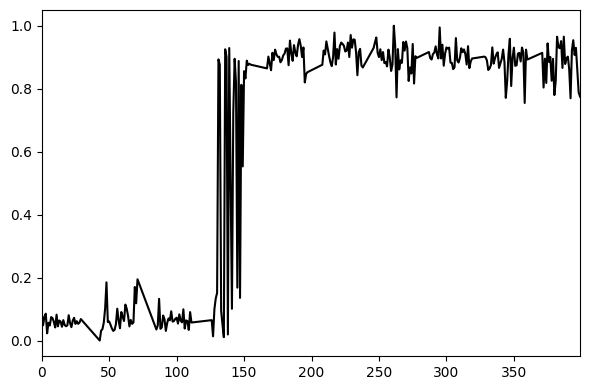

In [3]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

fig, axs = plt.subplots(1, 1, figsize=(6, 4))

batch_1d, labels = next(iter(train_data_1d))
y = batch_1d[0][0]
label = label_encoder.inverse_transform(labels)[0]
print(label)
# --- Plot the 1D graph ---
axs.plot(y, color='black')
axs.set_xlim(0, len(y)-1)

# Layout and show
plt.tight_layout()
plt.show()

In [4]:
from astro_model.model import JDLightCurve1DCNN6LBatchNormDropout
from astro_train.trainer import train_and_monitor
from torch import cuda

model = JDLightCurve1DCNN6LBatchNormDropout(2, in_channels=2)
device = 'cuda' if cuda.is_available() else 'cpu'

In [5]:
train_and_monitor(model, train_data_1d, 100, device=device, val_loader=test_data_1d, best_model_path=best_model_path, patience=10, log_file=log_file)

Epoch 1/100: 100%|██████████| 44/44 [00:08<00:00,  5.33it/s, Train Loss=0.5336, Train Acc=76.25%]


Validation Loss: 0.6302 | Validation Accuracy: 69.67%
Best model saved with accuracy: 69.67%


Epoch 2/100: 100%|██████████| 44/44 [00:07<00:00,  6.15it/s, Train Loss=0.4637, Train Acc=80.86%]


Validation Loss: 0.5991 | Validation Accuracy: 69.33%


Epoch 3/100: 100%|██████████| 44/44 [00:06<00:00,  6.37it/s, Train Loss=0.4062, Train Acc=82.89%]


Validation Loss: 0.5470 | Validation Accuracy: 80.50%
Best model saved with accuracy: 80.50%


... (30 outputs left out)

Epoch 19/100: 100%|██████████| 44/44 [00:06<00:00,  6.37it/s, Train Loss=0.3266, Train Acc=87.27%]


Validation Loss: 0.4505 | Validation Accuracy: 81.50%


Epoch 20/100: 100%|██████████| 44/44 [00:06<00:00,  6.50it/s, Train Loss=0.3019, Train Acc=88.36%]


Validation Loss: 0.4363 | Validation Accuracy: 82.33%
Early stopping triggered at epoch 20


In [6]:
from astro_test.test import print_evaluate
import torch

model.load_state_dict(torch.load(best_model_path, weights_only=True))

print_evaluate(model, test_data_1d, label_encoder, device)

/usr/local/lib/python3.10/dist-packages/torch/_utils.py:776: UserWarning: TypedStorage is deprecated. It will be removed in the future and UntypedStorage will be the only storage class. This should only matter to you if you are using storages directly.  To access UntypedStorage directly, use tensor.untyped_storage() instead of tensor.storage()
  return self.fget.__get__(instance, owner)()
100%|██████████| 19/19 [00:02<00:00,  7.31it/s]


Accuracy: 0.8283333333333334
Classification Report:
               precision    recall  f1-score   support

nonvariables       0.79      0.88      0.83       294
   variables       0.87      0.77      0.82       306

    accuracy                           0.83       600
   macro avg       0.83      0.83      0.83       600
weighted avg       0.83      0.83      0.83       600



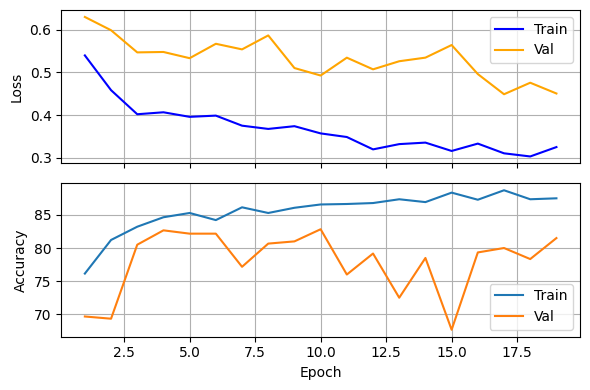

In [7]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.read_csv(log_file)

fig, (ax1, ax2) = plt.subplots(2, 1, sharex=True, figsize=(6, 4))

ax1.plot(df['epoch'], df['train_loss'], label='Train', color='blue')
ax1.plot(df['epoch'], df['val_loss'], label='Val', color='orange')
ax1.set_ylabel('Loss')
ax1.legend()
ax1.grid(True)

ax2.plot(df['epoch'], df['train_acc'], label='Train')
ax2.plot(df['epoch'], df['val_acc'], label='Val')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Accuracy')
ax2.legend()
ax2.grid(True)

plt.tight_layout()
plt.show()